#### Dependencies

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')

#### Initial Data Observations

`market_forward_excess_returns` is the target variable

In [2]:
%time
df = pd.read_csv('train.csv')
df.rename(columns={'market_forward_excess_returns': 'target'}, inplace=True)

CPU times: user 1 μs, sys: 1 μs, total: 2 μs
Wall time: 3.1 μs


In [3]:
df.info()
df.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8990 entries, 0 to 8989
Data columns (total 98 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date_id          8990 non-null   int64  
 1   D1               8990 non-null   int64  
 2   D2               8990 non-null   int64  
 3   D3               8990 non-null   int64  
 4   D4               8990 non-null   int64  
 5   D5               8990 non-null   int64  
 6   D6               8990 non-null   int64  
 7   D7               8990 non-null   int64  
 8   D8               8990 non-null   int64  
 9   D9               8990 non-null   int64  
 10  E1               7206 non-null   float64
 11  E10              7984 non-null   float64
 12  E11              7984 non-null   float64
 13  E12              7984 non-null   float64
 14  E13              7984 non-null   float64
 15  E14              7984 non-null   float64
 16  E15              7984 non-null   float64
 17  E16           

,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V3,V4,V5,V6,V7,V8,V9,forward_returns,risk_free_rate,target
0,0,0,0,0,1,1,0,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.002421,0.000301,-0.003038
1,1,0,0,0,1,1,0,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.008495,0.000303,-0.009114
2,2,0,0,0,1,0,0,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.009624,0.000301,-0.010243
3,3,0,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004662,0.000299,0.004046
4,4,0,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.011686,0.000299,-0.012301
5,5,0,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.006449,0.000300,-0.007066
6,6,0,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.003644,0.000298,0.003029
7,7,0,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.024566,0.000300,-0.025183
8,8,0,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.008492,0.000298,-0.009105
9,9,0,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.011263,0.000298,0.010649


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
date_id,8990.0,4494.500000,2595.333794,0.000000,2247.250000,4494.500000,6741.750000,8989.000000
D1,8990.0,0.031591,0.174917,0.000000,0.000000,0.000000,0.000000,1.000000
D2,8990.0,0.031591,0.174917,0.000000,0.000000,0.000000,0.000000,1.000000
D3,8990.0,0.047831,0.213420,0.000000,0.000000,0.000000,0.000000,1.000000
D4,8990.0,0.575195,0.494341,0.000000,0.000000,1.000000,1.000000,1.000000
...,...,...,...,...,...,...,...,...
V8,7984.0,0.303908,0.351109,0.000661,0.000661,0.101025,0.590030,1.000000
V9,4451.0,0.129227,1.277273,-1.497420,-0.738242,-0.170825,0.685907,12.997536
forward_returns,8990.0,0.000469,0.010551,-0.039754,-0.004324,0.000659,0.005900,0.040661
risk_free_rate,8990.0,0.000107,0.000088,-0.000004,0.000008,0.000095,0.000193,0.000317


A large number of NaN for the earliest `date_id`s.  
The `std` of the target variable is much larger than the mean -> noisy (daily fluctuations are larger than the average positive drift); `min` and `max` show extreme daily moves.

#### Distribution of the Target

In [5]:
mean = df['target'].mean()
median = df['target'].median()
skew = df['target'].skew()
kurt = df['target'].kurt()
print('Mean of the target: {:.5f}'.format(mean))
print('Median of the target: {:.5f}'.format(median))
print('Skewness of the target: {:.5f}'.format(skew))
print('Excess kurtosis of the target: {:.5f}'.format(kurt))

Mean of the target: 0.00005
Median of the target: 0.00025
Skewness of the target: -0.17795
Excess kurtosis of the target: 2.23848


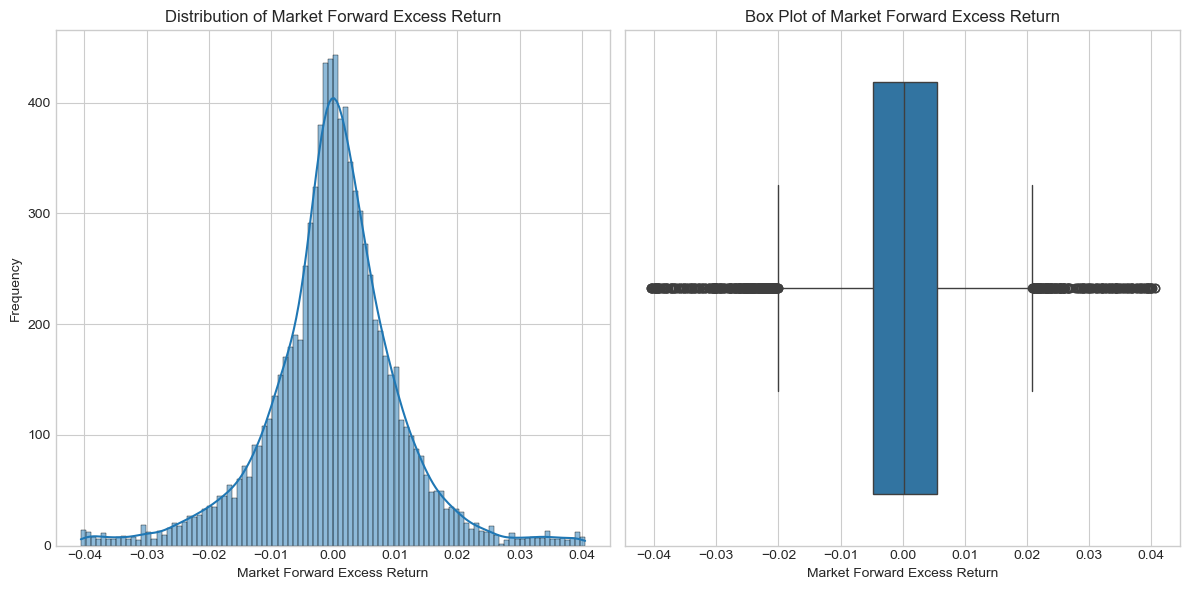

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Histogram and KDE
sns.histplot(df['target'], bins=100, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Market Forward Excess Return')
axes[0].set_xlabel('Market Forward Excess Return')
axes[0].set_ylabel('Frequency')

# Box plot
sns.boxplot(x=df['target'], ax=axes[1])
axes[1].set_title('Box Plot of Market Forward Excess Return')
axes[1].set_xlabel('Market Forward Excess Return')

plt.tight_layout()
plt.show()

1. Not a normal distribution
2. Excess kurtosis + box plot -> leptokurtic -> extreme events (large gains/losses) occur more frequently than a normal distribution would predict
3. Slightly negative skewness + (mean < median) -> a few large negative returns are slightly more common than arge positive returns

#### Temporal Dynamics of the Target

In [10]:
fig = px.line(df, x='date_id', y='target', title='Target Over Time')

# Add ±2 std dev reference lines
fig.add_hline(y=2 * df['target'].std(), line_color='red', line_dash='dash', annotation_text='+2σ')
fig.add_hline(y=-2 * df['target'].std(), line_color='red', line_dash='dash', annotation_text='-2σ')

fig.update_layout(
    xaxis_title='date_id',
    yaxis_title='market_forward_excess_return',
    template='plotly_white',
    hovermode='x unified'
)
fig.show()

Risk-adjusted returns: If we can predict volatility, then we can adjust our bet size accordingly. Should take a look at the `V*` features.  
Our model should adapt to changing marketing regimes rather than a static one.

#### Missing Data Analysis

In [33]:
missing_data_cols = df.columns[df.isna().any()]
missing_data_cols

Index(['E1', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18',
       'E19', 'E2', 'E20', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'I1',
       'I2', 'I3', 'I4', 'I5', 'I6', 'I7', 'I8', 'I9', 'M1', 'M10', 'M11',
       'M12', 'M13', 'M14', 'M15', 'M16', 'M17', 'M18', 'M2', 'M3', 'M4', 'M5',
       'M6', 'M7', 'M8', 'M9', 'P1', 'P10', 'P11', 'P12', 'P13', 'P2', 'P3',
       'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'S1', 'S10', 'S11', 'S12', 'S2',
       'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'V1', 'V10', 'V11', 'V12',
       'V13', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9'],
      dtype='object')

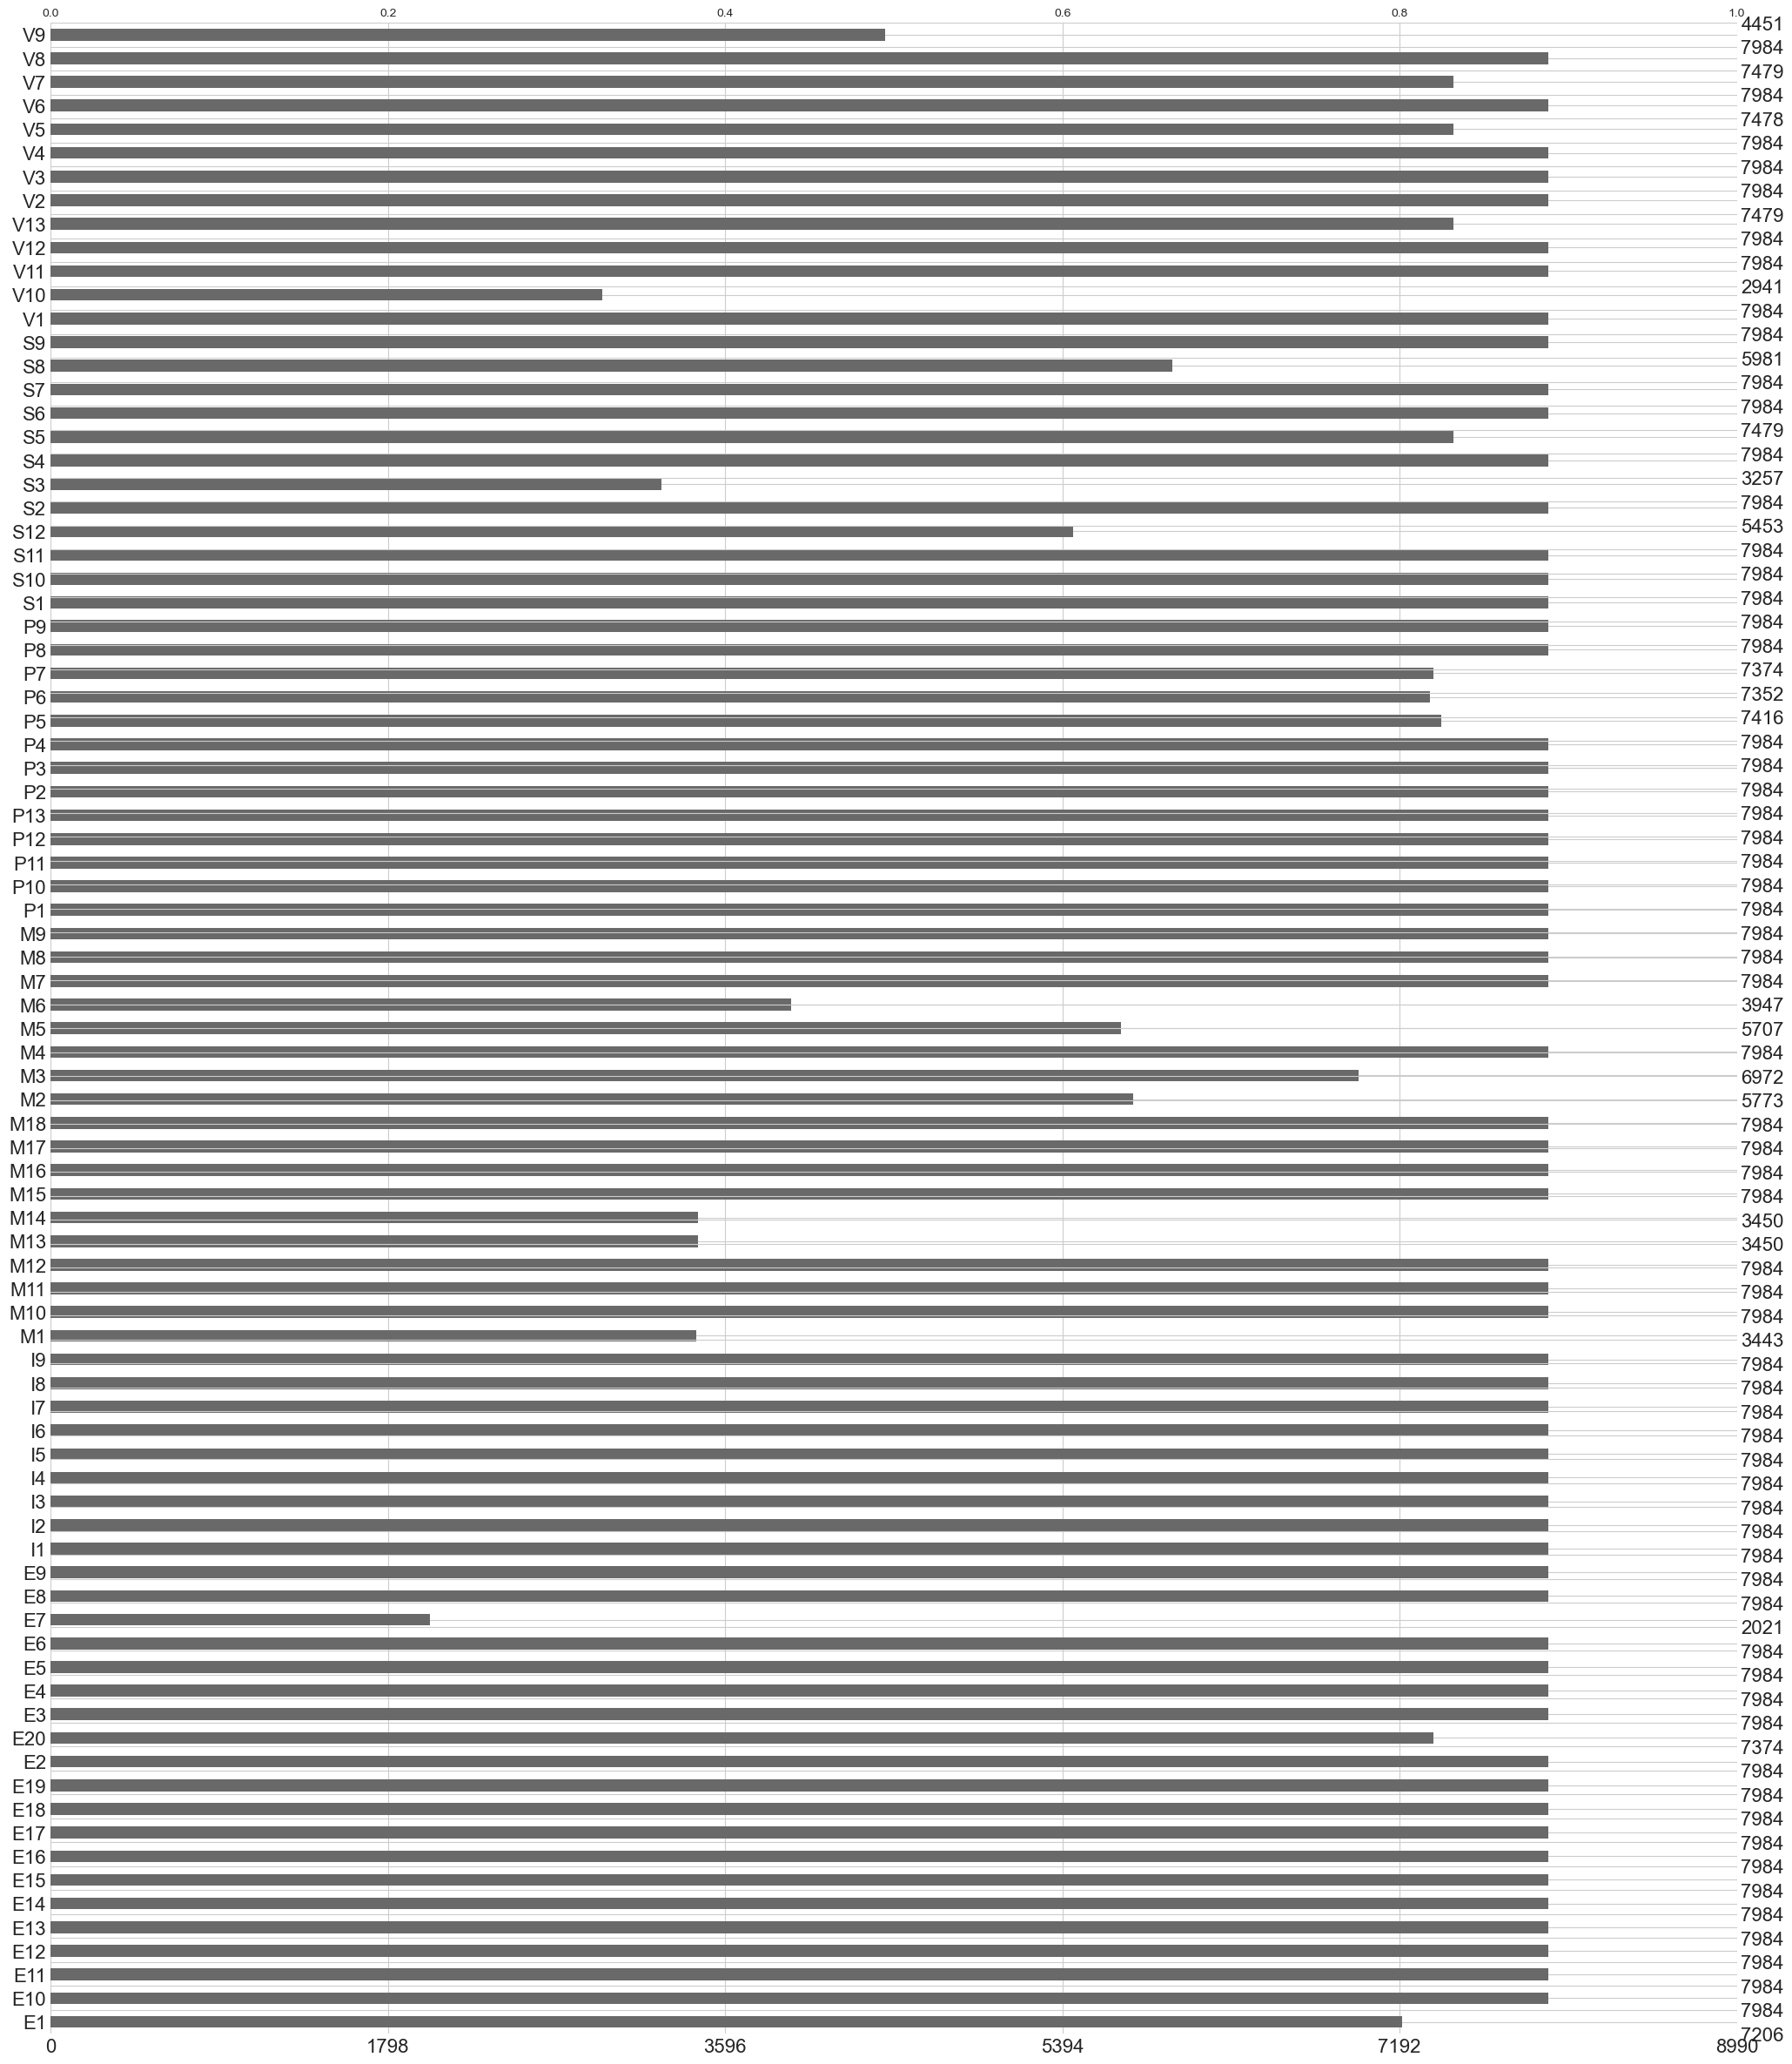

In [34]:
msno.bar(df[missing_data_cols])
plt.show()

<Figure size 1200x600 with 0 Axes>

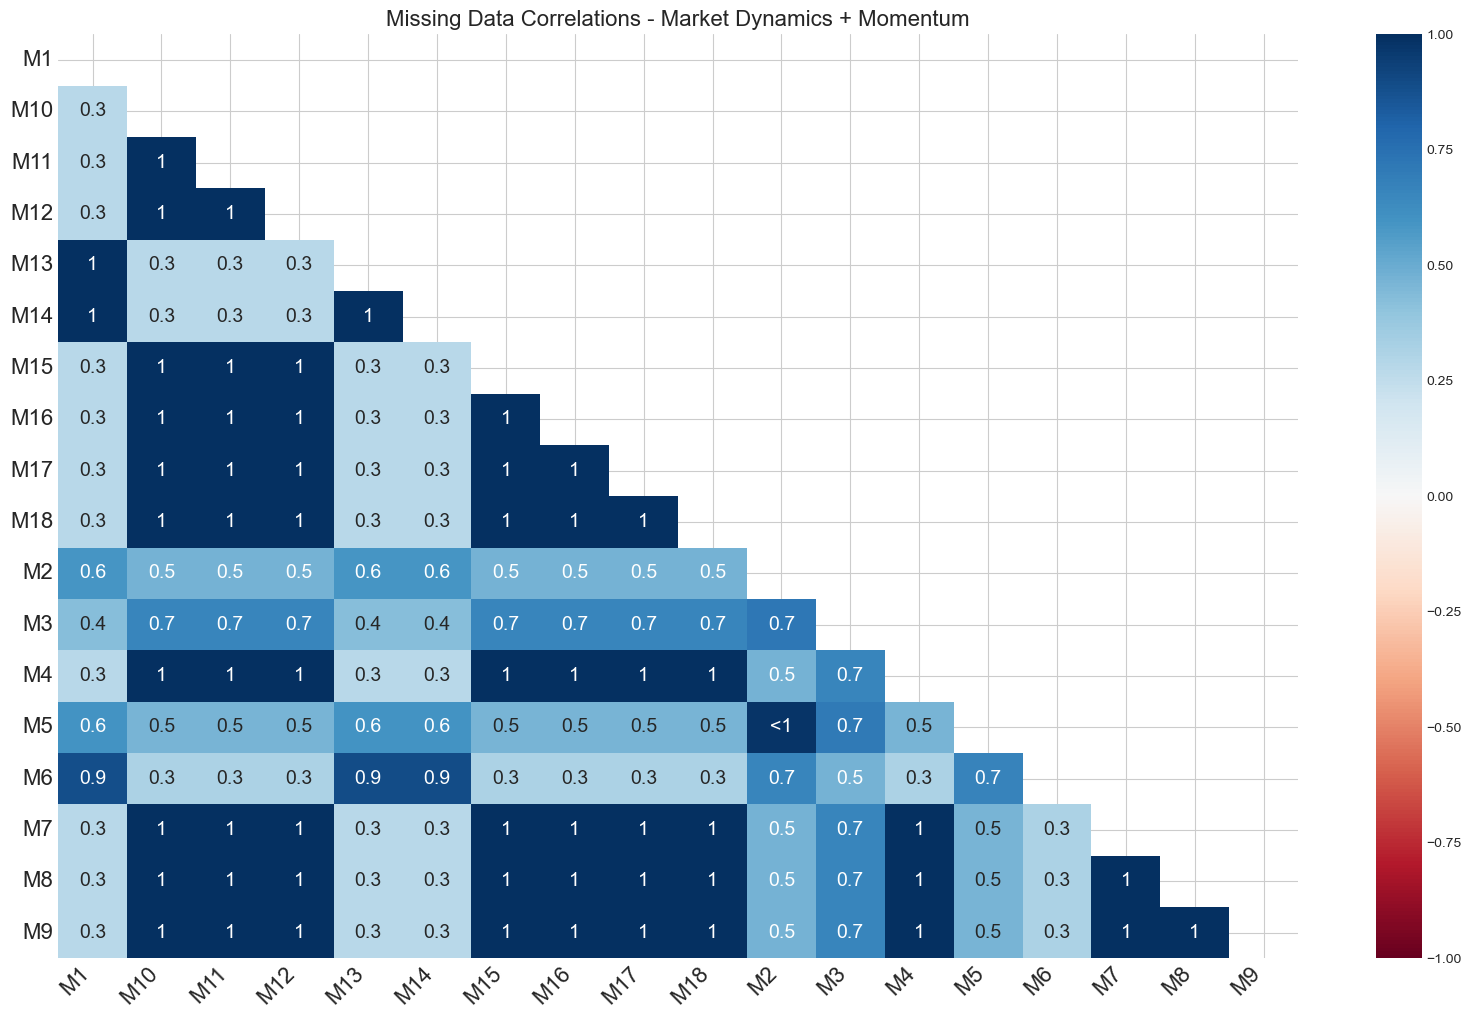

<Figure size 1200x600 with 0 Axes>

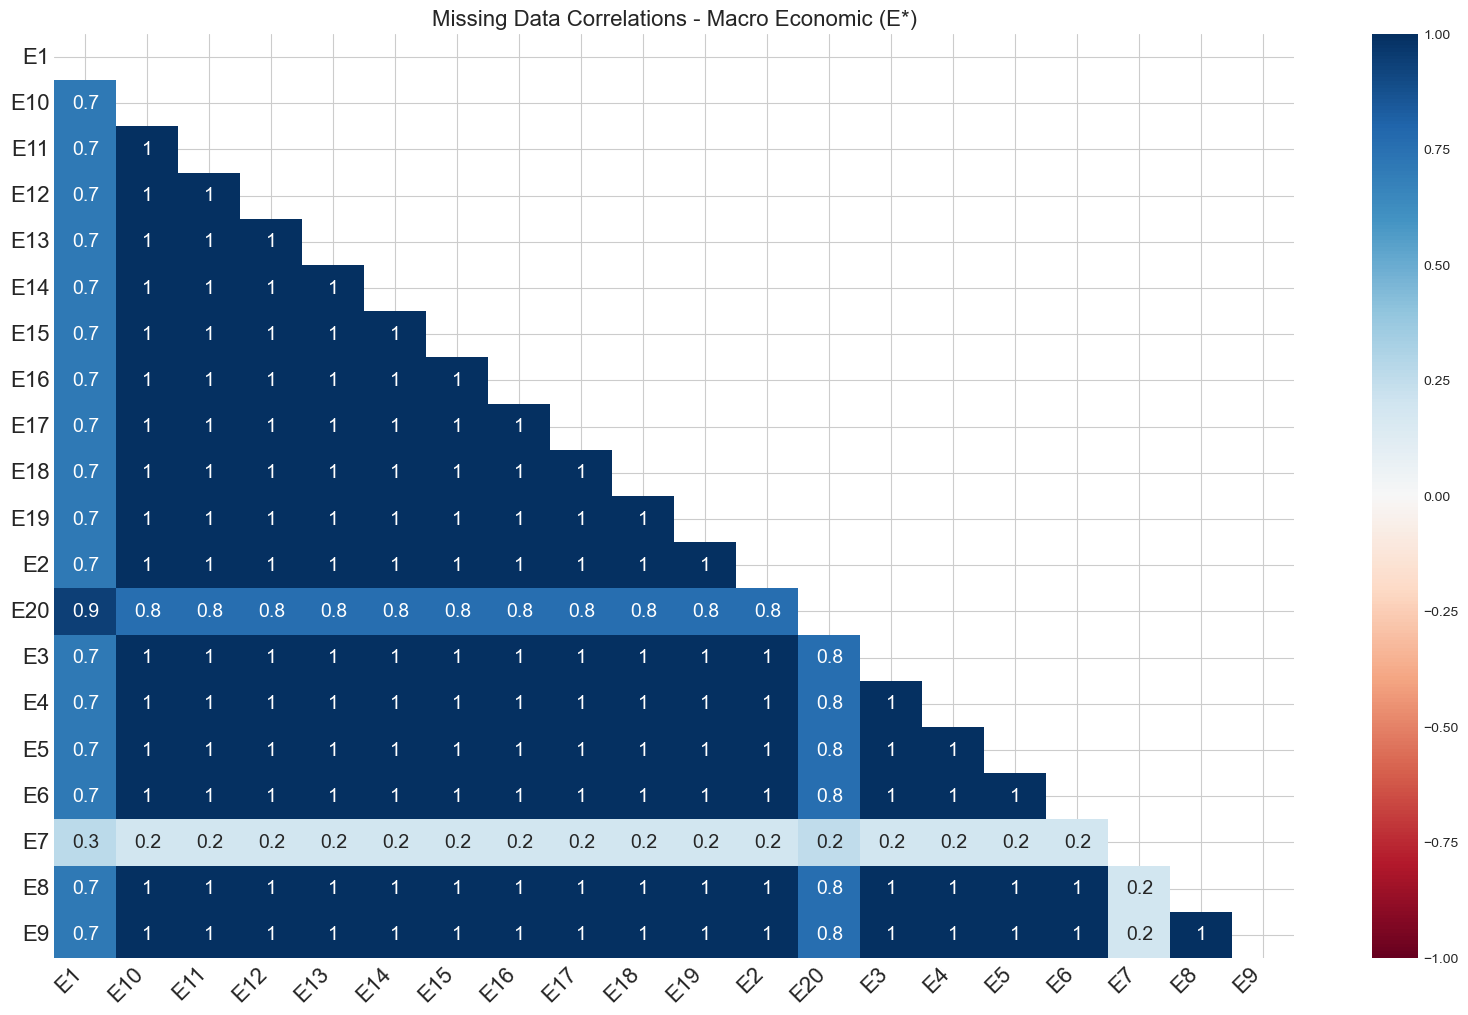

<Figure size 1200x600 with 0 Axes>

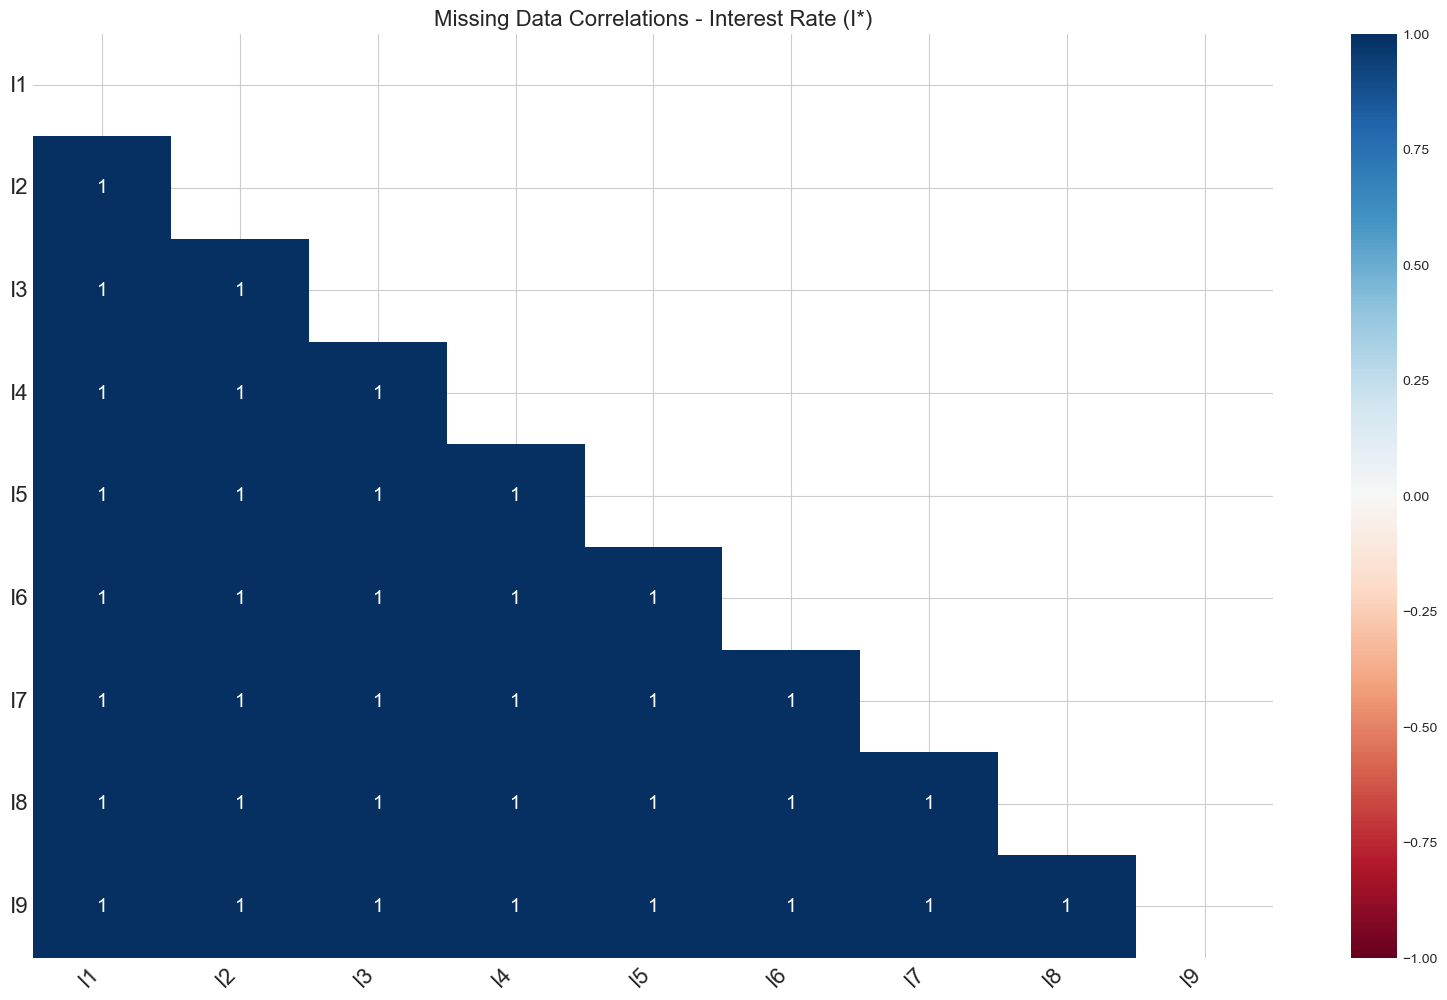

<Figure size 1200x600 with 0 Axes>

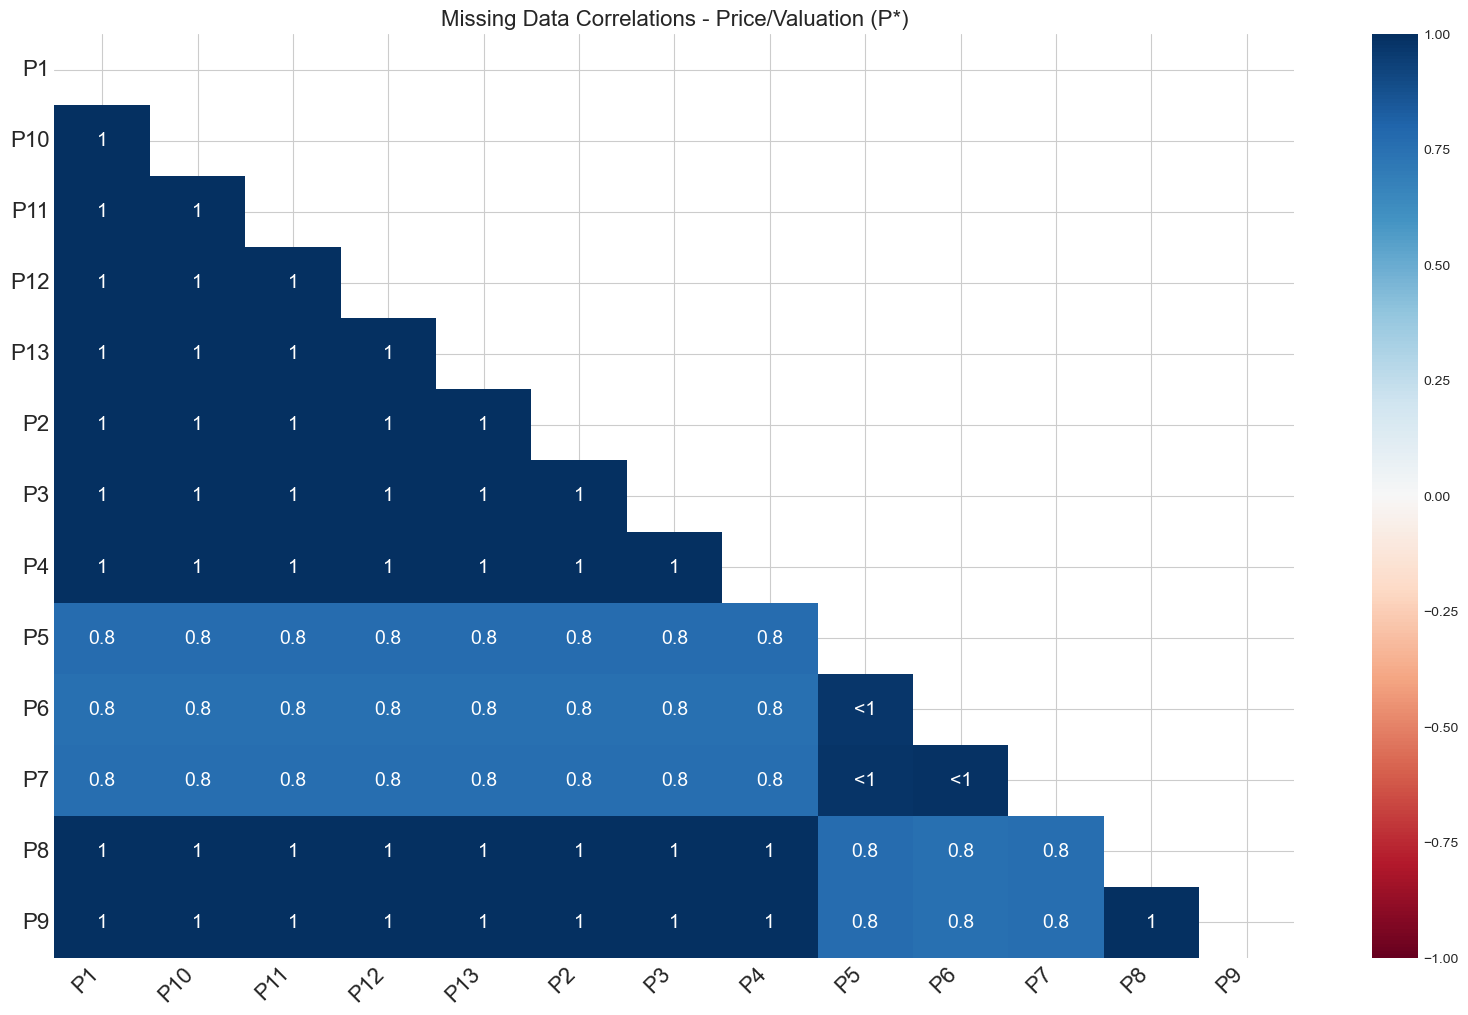

<Figure size 1200x600 with 0 Axes>

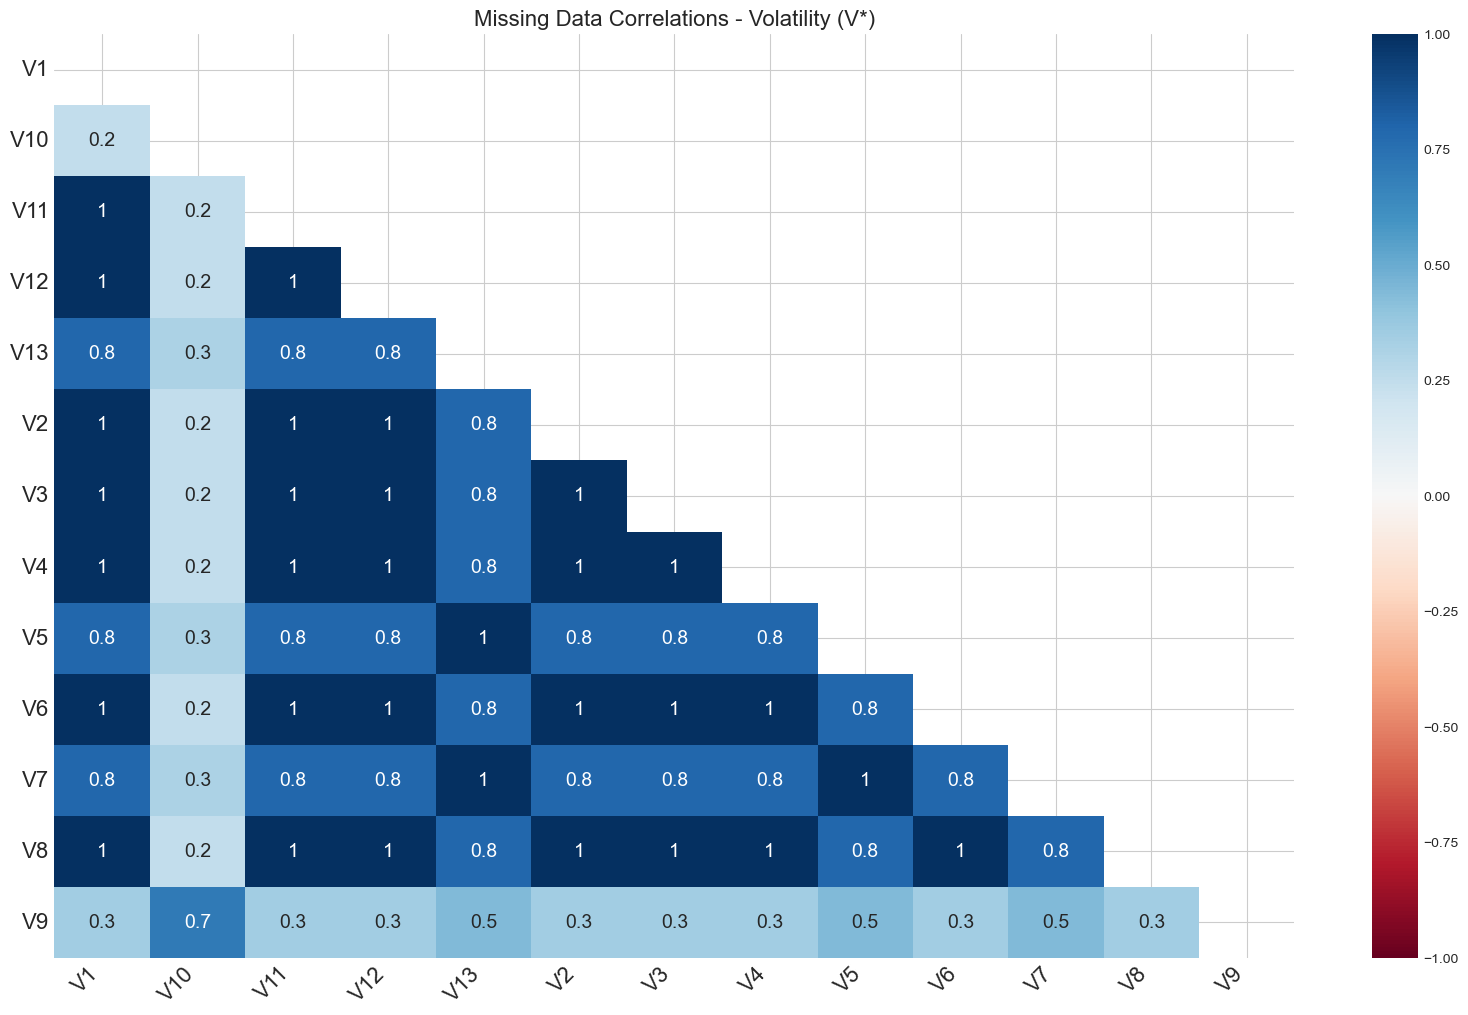

<Figure size 1200x600 with 0 Axes>

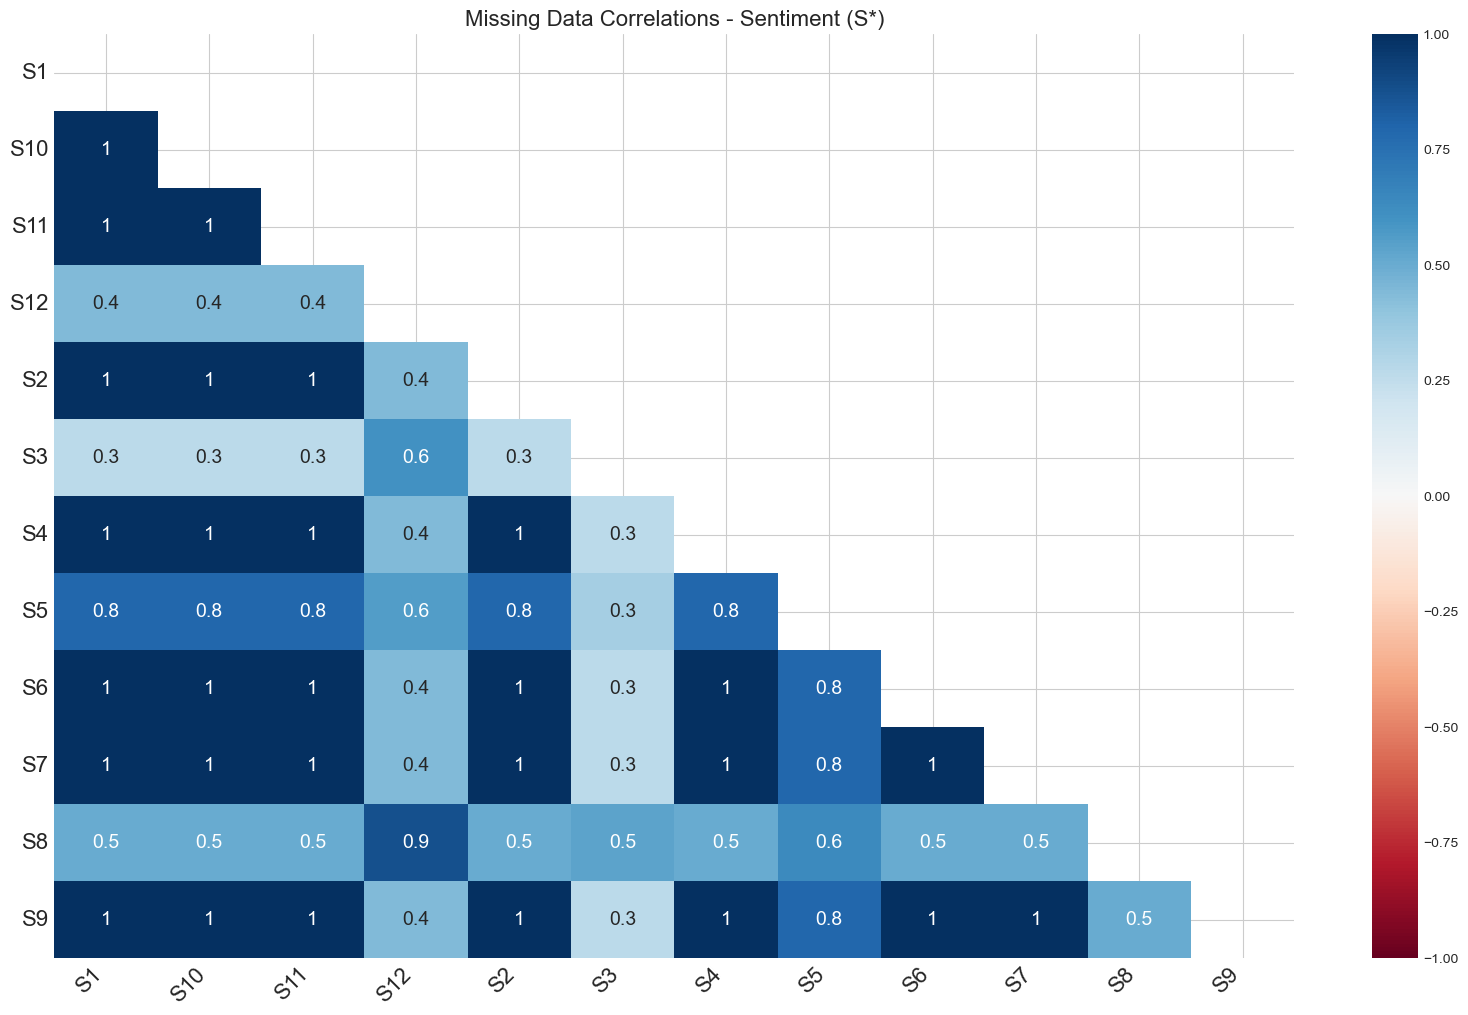

In [55]:
M_cols = [c for c in df.columns if c.startswith('M')]
E_cols = [c for c in df.columns if c.startswith('E')]
I_cols = [c for c in df.columns if c.startswith('I')]
P_cols = [c for c in df.columns if c.startswith('P')]
V_cols = [c for c in df.columns if c.startswith('V')]
S_cols = [c for c in df.columns if c.startswith('S')]

groups = {
    "Market Dynamics + Momentum": M_cols,
    "Macro Economic (E*)": E_cols,
    "Interest Rate (I*)": I_cols,
    "Price/Valuation (P*)": P_cols,
    "Volatility (V*)": V_cols,
    "Sentiment (S*)": S_cols,
}

for group_name, cols in groups.items():
    plt.figure(figsize=(12, 6))
    msno.heatmap(df[cols])
    plt.title('Missing Data Correlations - {}'.format(group_name), fontsize=16)
    plt.show()